<a href="https://www.kaggle.com/code/rhemaugwuede/student?scriptVersionId=369651113" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import csv
import pandas as pd

Saving the CSV file as a varibale 'FILENAME'

In [2]:
FILENAME = "students.csv"

Recording the table data

In [3]:
header = ["name", "grade", "study_hours", "attendance", "score"]
rows = [
    ["Ava", 9, 4.5, 95, 82],
    ["Liam", 9, 6.0, 98, 91],
    ["Sophia", 10, 3.5, 89, 76],
    ["Noah", 10, 7.0, 99, 94],
    ["Emma", 11, 5.5, 93, 88],
    ["Oliver", 11, 8.0, 97, 96],
    ["Mia", 12, 4.0, 91, 79],
    ["Ethan", 12, 6.5, 96, 90],
    ["Isabella", 9, 7.5, 100, 97],
    ["Lucas", 10, 2.5, 85, 68],
    ["Amelia", 11, 6.0, 94, 92],
    ["James", 12, 5.0, 90, 84],
]

Writing to the csv file

In [4]:
# Write the full dataset to a CSV file 
with open(FILENAME, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(header)
    writer.writerows(rows)
print(f"Wrote {len(rows)} students to {FILENAME}\n")

Wrote 12 students to students.csv



Reading the CSV file using pandas

In [5]:
df = pd.read_csv(FILENAME)

Viewing the table as a whole

In [6]:
df.head

<bound method NDFrame.head of         name  grade  study_hours  attendance  score
0        Ava      9          4.5          95     82
1       Liam      9          6.0          98     91
2     Sophia     10          3.5          89     76
3       Noah     10          7.0          99     94
4       Emma     11          5.5          93     88
5     Oliver     11          8.0          97     96
6        Mia     12          4.0          91     79
7      Ethan     12          6.5          96     90
8   Isabella      9          7.5         100     97
9      Lucas     10          2.5          85     68
10    Amelia     11          6.0          94     92
11     James     12          5.0          90     84>

Requesting the composition of the DataFrame

In [7]:
df.shape

(12, 5)

Viewing the first three rows

In [8]:
df.head(3)

,name,grade,study_hours,attendance,score
0,Ava,9,4.5,95,82
1,Liam,9,6.0,98,91
2,Sophia,10,3.5,89,76


Getting info about the columns

In [9]:
df.columns

Index(['name', 'grade', 'study_hours', 'attendance', 'score'], dtype='object')

In [10]:
score = df['score']

Calculating average score 

In [11]:
average_score = score.mean()
print(f'Average Score: {average_score:.2f}')

Average Score: 86.42


Max and mean scores

In [12]:
max_score = score.max()
min_score = score.min()
print(f'Max Score: {max_score}')
print(f'Min Score: {min_score}')



Max Score: 97
Min Score: 68


Median Scores

In [13]:
median_score = score.median()
print(f'Median Score : {median_score}')

Median Score : 89.0


Getting statiscal data for the score column.

In [14]:
print(score.describe())

count    12.000000
mean     86.416667
std       8.826183
min      68.000000
25%      81.250000
50%      89.000000
75%      92.500000
max      97.000000
Name: score, dtype: float64


Getting statiscal data for the entire csv file.

In [15]:
df.describe()

,grade,study_hours,attendance,score
count,12.000000,12.000000,12.000000,12.000000
mean,10.500000,5.500000,93.916667,86.416667
std,1.167748,1.665151,4.501683,8.826183
min,9.000000,2.500000,85.000000,68.000000
25%,9.750000,4.375000,90.750000,81.250000
50%,10.500000,5.750000,94.500000,89.000000
75%,11.250000,6.625000,97.250000,92.500000
max,12.000000,8.000000,100.000000,97.000000


Conditional selection

In [16]:
highest_scorers = df[df['score'] >= 90]
print(highest_scorers)

        name  grade  study_hours  attendance  score
1       Liam      9          6.0          98     91
3       Noah     10          7.0          99     94
5     Oliver     11          8.0          97     96
7      Ethan     12          6.5          96     90
8   Isabella      9          7.5         100     97
10    Amelia     11          6.0          94     92


Paired Conditional Selection. "|"for OR

In [17]:
top_students = df[
(df['score']>=90) &
(df['attendance'] >85)
]
print(top_students)

        name  grade  study_hours  attendance  score
1       Liam      9          6.0          98     91
3       Noah     10          7.0          99     94
5     Oliver     11          8.0          97     96
7      Ethan     12          6.5          96     90
8   Isabella      9          7.5         100     97
10    Amelia     11          6.0          94     92


Searching specifics


In [18]:
df.loc[df['score'].idxmax()]

name           Isabella
grade                 9
study_hours         7.5
attendance          100
score                97
Name: 8, dtype: object

Data grouping

In [19]:
grade_grouping = df.groupby('grade')['score']
for grade, scores in grade_grouping:
    print(f"Grade: {grade},Scores in grade {grade}: {list(scores)}, Max Score in grade {grade}: {scores.max()}")

Grade: 9,Scores in grade 9: [82, 91, 97], Max Score in grade 9: 97
Grade: 10,Scores in grade 10: [76, 94, 68], Max Score in grade 10: 94
Grade: 11,Scores in grade 11: [88, 96, 92], Max Score in grade 11: 96
Grade: 12,Scores in grade 12: [79, 90, 84], Max Score in grade 12: 90


calculations on grouped data

In [20]:
grade_grouping.mean().round(2)

grade
9     90.00
10    79.33
11    92.00
12    84.33
Name: score, dtype: float64

Summary of group data

In [21]:
grade_grouping.agg(
    ['mean', 'max', 'min', 'count']
)

,mean,max,min,count
grade,,,,
9,90.000000,97,82,3
10,79.333333,94,68,3
11,92.000000,96,88,3
12,84.333333,90,79,3


Implementing matplotlib

Text(0.5, 1.0, 'Rel between Study Hours and Test Score')

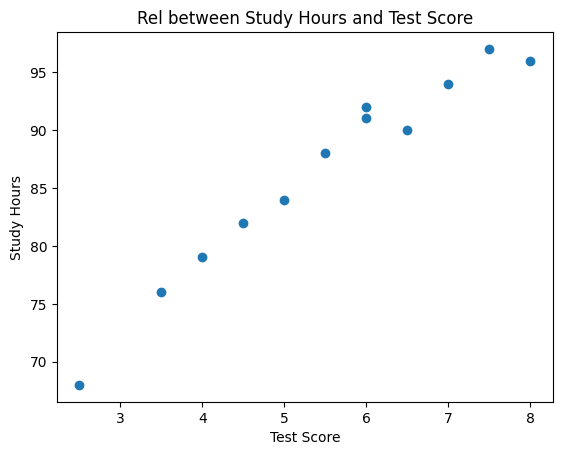

In [22]:
import matplotlib.pyplot as plt
plt.scatter(df['study_hours'], df['score'])
plt.xlabel('Test Score')
plt.ylabel('Study Hours')
plt.title('Rel between Study Hours and Test Score')

Changing the form

Text(0.5, 1.0, 'Score by grades')

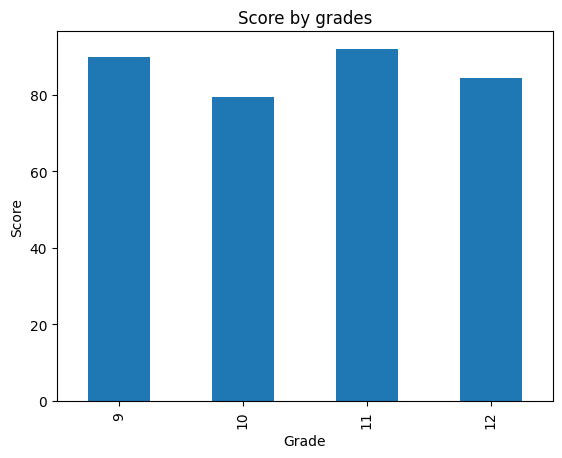

In [23]:
grade_grouping.mean().plot(kind='bar')
plt.xlabel('Grade')
plt.ylabel('Score')
plt.title('Score by grades')
